## Perceptrón de Rosenblatt — Compuerta AND (codificación bipolar)

Implementación del algoritmo de aprendizaje de Rosenblatt para entrenar un perceptrón simple.
Se usa **codificación bipolar**: `1` para verdadero y `-1` para falso (NOT).

In [48]:
!conda install numpy pandas matplotlib seaborn scikit-learn -y

2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
Solving environment: done


==> WARNING: A newer version of conda exists. <==
    current version: 26.9.3
    latest version: 26.9.4

Please update conda by running

    $ conda self update



# All requested packages already installed.



In [49]:
# Importación de bibliotecas
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print(f"NumPy:        {np.__version__}")
print(f"Pandas:       {pd.__version__}")
print(f"Matplotlib:   {plt.matplotlib.__version__}")
print(f"Scikit-learn: {sklearn.__version__}")
print("\nBibliotecas cargadas correctamente.")

NumPy:        2.4.6
Pandas:       3.1.0
Matplotlib:   3.11.2
Scikit-learn: 1.9.1

Bibliotecas cargadas correctamente.


## 1. Datos de entrenamiento — Compuerta AND (bipolar)

Se usa codificación bipolar donde `-1` representa el caso NOT (falso) y `1` representa verdadero.

| x₁ | x₂ | bias | y (AND bipolar) |
|----|-----|------|----------------|
| -1 | -1  |   1  |      -1        |
| -1 |  1  |   1  |      -1        |
|  1 | -1  |   1  |      -1        |
|  1 |  1  |   1  |       1        |

In [50]:
# Vector X: matriz de entradas (4 muestras × 3 características)
# Columnas: [x1, x2, bias]
# Codificación bipolar: -1 = NOT (falso), 1 = verdadero
X = np.array([
    [-1, -1, 1],
    [-1,  1, 1],
    [ 1, -1, 1],
    [ 1,  1, 1]
], dtype=float)

# Vector y: etiquetas de salida AND bipolar (columna)
y = np.array([-1, -1, -1, 1], dtype=float)

print("Matriz X (entradas + bias):")
print(X)
print("\nVector y (salidas AND bipolar):")
print(y)

Matriz X (entradas + bias):
[[-1. -1.  1.]
 [-1.  1.  1.]
 [ 1. -1.  1.]
 [ 1.  1.  1.]]

Vector y (salidas AND bipolar):
[-1. -1. -1.  1.]


## 2. Algoritmo de Rosenblatt

Regla de actualización de pesos:

$$w \leftarrow w + \eta \cdot (y_i - \hat{y}_i) \cdot x_i$$

Donde:
- $\eta$ es la tasa de aprendizaje
- $\hat{y}_i = \text{sign}(w^T x_i)$ es la predicción actual
- La función signo devuelve `1` si la entrada > 0 y `-1` si la entrada ≤ 0

In [60]:
# Parámetros del perceptrón
eta       = 0.1   # Tasa de aprendizaje
epochs    = 4    # Número máximo de épocas
n_samples = X.shape[0]

# Pesos iniciales aleatorios (incluye el peso del bias)
np.random.seed(42)
w = np.random.randn(X.shape[1])  # vector 1D de shape (3,)

print("Pesos iniciales (w):")
print(w)

# Función de activación signo (bipolar)
def sign(z):
    """Devuelve 1 si z > 0, -1 en caso contrario (codificación bipolar)."""
    return 1.0 if z > 0 else -1.0


Pesos iniciales (w):
[ 0.49671415 -0.1382643   0.64768854]


Época  1 | Muestra 1 | Predicción: 1.0 | Error: -2.0 | Pesos: [0.69671415 0.0617357  0.44768854]
Época  1 | Muestra 2 | Predicción: -1.0 | Error: 0.0 | Pesos: [0.69671415 0.0617357  0.44768854]
Época  1 | Muestra 3 | Predicción: 1.0 | Error: -2.0 | Pesos: [0.49671415 0.2617357  0.24768854]
Época  1 | Muestra 4 | Predicción: 1.0 | Error: 0.0 | Pesos: [0.49671415 0.2617357  0.24768854]
Época  1 | Errores: 2
Época  1 | Errores: 2
Época  2 | Muestra 1 | Predicción: -1.0 | Error: 0.0 | Pesos: [0.49671415 0.2617357  0.24768854]
Época  2 | Muestra 2 | Predicción: 1.0 | Error: -2.0 | Pesos: [0.69671415 0.0617357  0.04768854]
Época  2 | Muestra 3 | Predicción: 1.0 | Error: -2.0 | Pesos: [ 0.49671415  0.2617357  -0.15231146]
Época  2 | Muestra 4 | Predicción: 1.0 | Error: 0.0 | Pesos: [ 0.49671415  0.2617357  -0.15231146]
Época  2 | Errores: 2
Época  2 | Errores: 2
Época  3 | Muestra 1 | Predicción: -1.0 | Error: 0.0 | Pesos: [ 0.49671415  0.2617357  -0.15231146]
Época  3 | Muestra 2 | Predicció

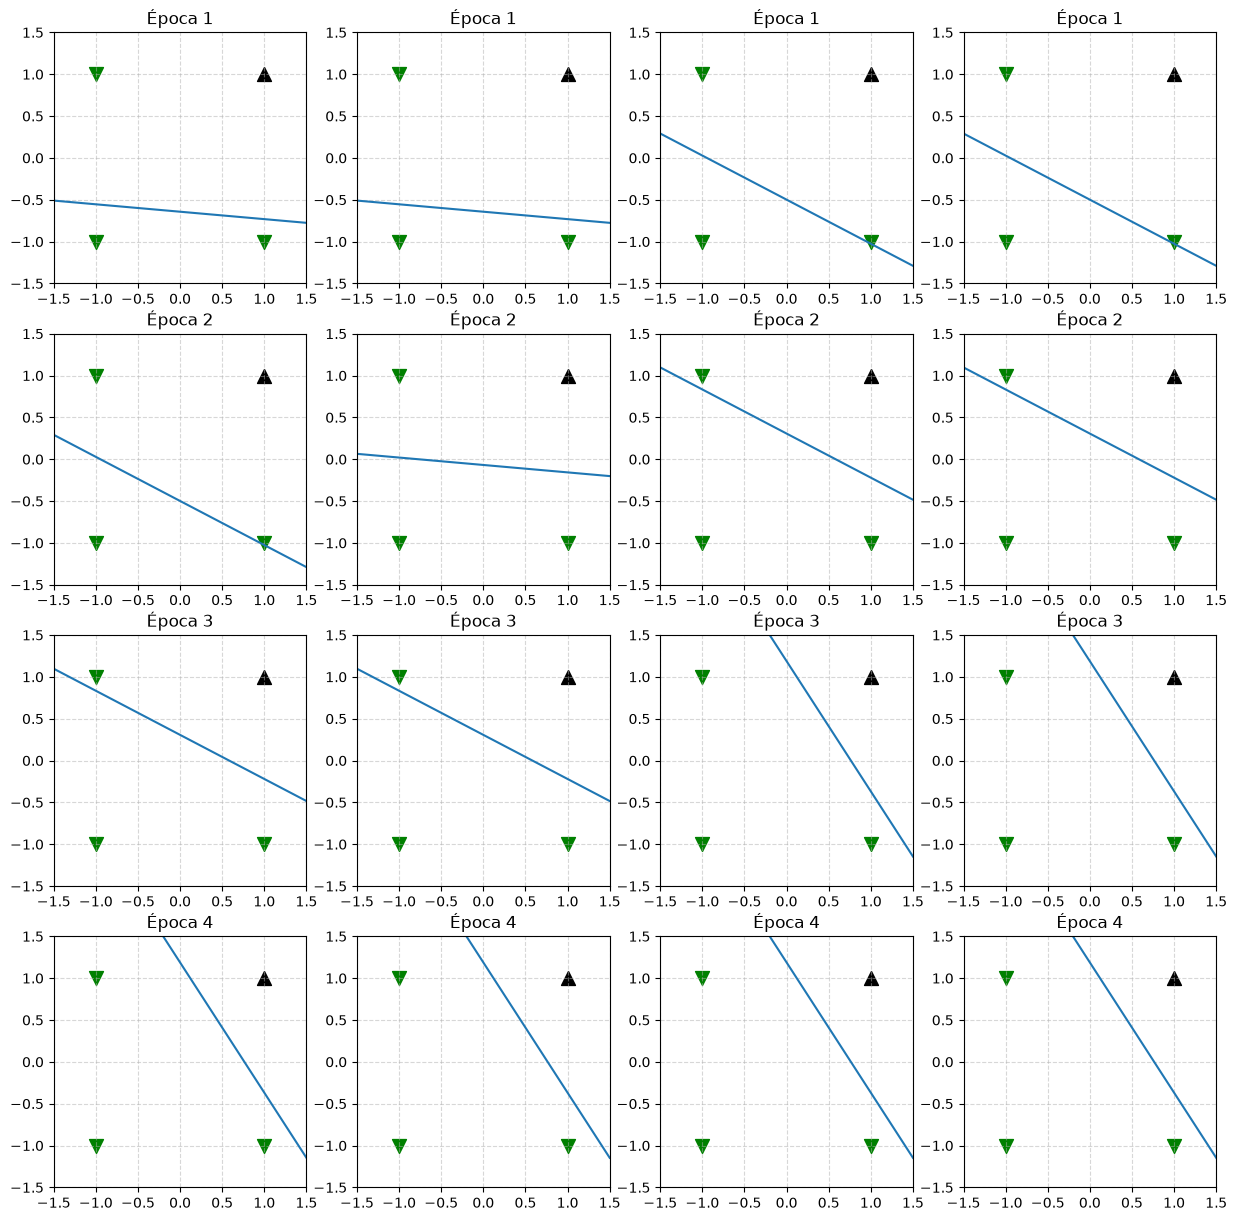

In [61]:
plt.rcParams["figure.figsize"] = (15,15)
fig, axs = plt.subplots(4, 4)
index = 0


history = []  # Registro de errores por época

for epoch in range(1, epochs + 1):
    errors = 0
    for i in range(n_samples):
        xi    = X[i]              # vector fila, shape (3,)
        yi    = y[i]              # etiqueta real (escalar)
        y_hat = sign(xi @ w)      # predicción: producto punto + funcion signo
        error = yi - y_hat        # diferencia
        w    += eta * error * xi  # actualización de pesos
        if error != 0:
            errors += 1
            
            
        print(f"Época {epoch:2d} | Muestra {i+1} | Predicción: {y_hat} | Error: {error} | Pesos: {w}")
        ax = axs[index//4, index%4]
        
        # Separamos los puntos por clases usando máscaras de numpy
        clase_negativa = (y == -1)
        clase_positiva = (y == 1)
        
        # Graficar la clase -1 (Triángulos hacia abajo verdes)
        ax.scatter(X[clase_negativa, 0], X[clase_negativa, 1], 
                marker='v', color='green', s=100, label='Falso (-1)')
        
        # Graficar la clase +1 (Triángulos hacia arriba negros)
        ax.scatter(X[clase_positiva, 0], X[clase_positiva, 1], 
                marker='^', color='black', s=100, label='Verdadero (1)')
        
        # Graficar la línea de decisión
        xx = np.linspace(-1.5, 1.5, 10)
        yy = (-w[2] -w[1]*xx)/w[0]
        ax.plot(xx, yy)
        
        # FIJAR LOS LÍMITES PARA EVITAR EL ZOOM AUTOMÁTICO
        ax.set_xlim(-1.5, 1.5)
        ax.set_ylim(-1.5, 1.5)
        ax.set_title(f"Época {epoch}")
        ax.grid(True, linestyle='--', alpha=0.5)
        
        
        index += 1


    history.append(errors)
    print(f"Época {epoch:2d} | Errores: {errors}")
    if errors == 0:
        print(f"\nConvergencia alcanzada en la época {epoch}.")
        break
    print(f"Época {epoch:2d} | Errores: {errors}")
    if errors == 0:
        print(f"\nConvergencia alcanzada en la época {epoch}.")
        break

print("\nPesos finales (w):")
print(w)

In [62]:
# Verificación de las predicciones
print("Verificación final:")
print(f"{'x1':>4} {'x2':>4} | {'y_real':>7} | {'y_pred':>7} | {'estado':>5} |")
print("-" * 40)
for i in range(n_samples):
    xi     = X[i]
    y_real = int(y[i])
    y_pred = int(sign(xi @ w))
    x1, x2 = int(xi[0]), int(xi[1])
    ok = "(ok)" if y_real == y_pred else "X"
    print(f"{x1:>4} {x2:>4} | {y_real:>7} | {y_pred:>7} | {ok}")

Verificación final:
  x1   x2 |  y_real |  y_pred | estado |
----------------------------------------
  -1   -1 |      -1 |      -1 | (ok)
  -1    1 |      -1 |      -1 | (ok)
   1   -1 |      -1 |      -1 | (ok)
   1    1 |       1 |       1 | (ok)


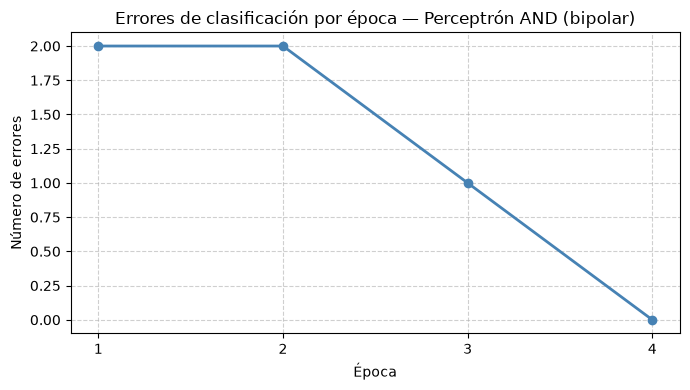

In [63]:
# Gráfica de errores por época
plt.figure(figsize=(7, 4))
plt.plot(range(1, len(history) + 1), history, marker='o', color='steelblue', linewidth=2)
plt.title('Errores de clasificación por época — Perceptrón AND (bipolar)')
plt.xlabel('Época')
plt.ylabel('Número de errores')
plt.xticks(range(1, len(history) + 1))
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()